# Model Testing

### Importing Required Libraries 

In [2]:
import cv2
import os
import time
import numpy as np
import mediapipe as mp

# Compatibility shim: mediapipe 0.10.30+ moved solutions to mediapipe.python.solutions
if not hasattr(mp, 'solutions'):
    import mediapipe.python.solutions as _solutions
    mp.solutions = _solutions

from tensorflow import keras
from matplotlib import pyplot as plt


2026-03-13 17:43:16.484830: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-13 17:43:16.753085: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-13 17:43:17.114252: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-03-13 17:43:17.424897: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-03-13 17:43:17.426915: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-03-13 17:43:17.921096: I tensorflow/core/platform/cpu_feature_guard.cc:

### Implementation of Mediapipe

In [3]:
mp_holistic = mp.solutions.holistic # Holistic model
mp_drawing = mp.solutions.drawing_utils # Drawing utilities

def mediapipe_detection(image, model):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # COLOR CONVERSION BGR 2 RGB
    image.flags.writeable = False                  # Image is no longer writeable
    results = model.process(image)                 # Make prediction
    image.flags.writeable = True                   # Image is now writeable 
    image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR) # COLOR COVERSION RGB 2 BGR
    return image, results

In [4]:
def draw_landmarks(image, results):
    
    mp_drawing.draw_landmarks(image, results.pose_landmarks, mp_holistic.POSE_CONNECTIONS)       # Draw pose connections
    mp_drawing.draw_landmarks(image, results.left_hand_landmarks, mp_holistic.HAND_CONNECTIONS)  # Draw left hand connections
    mp_drawing.draw_landmarks(image, results.right_hand_landmarks, mp_holistic.HAND_CONNECTIONS) # Draw right hand connections

In [5]:
def draw_styled_landmarks(image, results):
    # Draw pose connections
    mp_drawing.draw_landmarks(image, results.pose_landmarks, mp_holistic.POSE_CONNECTIONS,
                             mp_drawing.DrawingSpec(color=(80,22,10), thickness=2, circle_radius=4), 
                             mp_drawing.DrawingSpec(color=(80,44,121), thickness=2, circle_radius=2)
                             ) 
    # Draw left hand connections
    mp_drawing.draw_landmarks(image, results.left_hand_landmarks, mp_holistic.HAND_CONNECTIONS, 
                             mp_drawing.DrawingSpec(color=(0,255,127), thickness=2, circle_radius=4), 
                             mp_drawing.DrawingSpec(color=(0,255,127), thickness=2, circle_radius=2)
                             ) 
    # Draw right hand connections  
    mp_drawing.draw_landmarks(image, results.right_hand_landmarks, mp_holistic.HAND_CONNECTIONS, 
                             mp_drawing.DrawingSpec(color=(0,255,127), thickness=2, circle_radius=4), 
                             mp_drawing.DrawingSpec(color=(0,255,127), thickness=2, circle_radius=2)
                             ) 

In [6]:
def extract_keypoints(results):
    pose = np.array([[res.x, res.y, res.z, res.visibility] for res in results.pose_landmarks.landmark]).flatten() if results.pose_landmarks else np.zeros(33*4)

    lh = np.array([[res.x, res.y, res.z] for res in results.left_hand_landmarks.landmark]).flatten() if results.left_hand_landmarks else np.zeros(21*3)
    rh = np.array([[res.x, res.y, res.z] for res in results.right_hand_landmarks.landmark]).flatten() if results.right_hand_landmarks else np.zeros(21*3)
    return np.concatenate([pose, lh, rh])

In [7]:
# Calling the Trained Model (using patched h5 for Keras 3 compatibility)
model=keras.models.load_model('isl6_patched.h5')


2026-03-13 17:43:31.375248: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-03-13 17:43:31.376409: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [8]:
colors = [(245,23,16),(245,23,16),(245,23,16),(245,23,16),(245,23,16),(245,23,16)]
def prob_viz(res, actions, input_frame, colors):
    output_frame = input_frame.copy()
    for num, prob in enumerate(res):
        cv2.rectangle(output_frame, (0,60+num*40),(int(prob*100),90+num*40), colors[num], -1)
        cv2.putText(output_frame, actions[num], (0, 85+num*40), cv2.FONT_HERSHEY_SIMPLEX, 1,(255,255,255), 2, cv2.LINE_AA)
        
    return output_frame

In [9]:
actions = np.array(["HI","THANKS","FISH","COW","PLANE","CYCLING"])

### Implementation of Recoginition Model

In [ ]:

import threading, queue, time, json, socket
from http.server import HTTPServer, BaseHTTPRequestHandler
from urllib.parse import urlparse
import ipywidgets as widgets
from IPython.display import display

# ── Shared queues & state ──────────────────────────────────────────
frame_q      = queue.Queue(maxsize=2)
result_q     = queue.Queue(maxsize=2)
prediction_q = queue.Queue(maxsize=1)   # latest prediction text
sequence     = []
sentence     = []
THRESHOLD    = 0.7
SEQUENCE_LEN = 20

# ── Try to initialise MediaPipe Holistic ───────────────────────────
_holistic = None
_mp_ok    = False
try:
    _holistic = mp.solutions.holistic.Holistic(
        min_detection_confidence=0.5, min_tracking_confidence=0.5)
    _mp_ok = True
    print("✓ MediaPipe Holistic ready — sign recognition active")
except Exception as e:
    print(f"✗ MediaPipe Holistic unavailable ({e.__class__.__name__})")

# ── Background inference worker ────────────────────────────────────
def inference_worker():
    while True:
        jpg_bytes = frame_q.get()
        if jpg_bytes is None:
            break
        import numpy as _np
        nparr = _np.frombuffer(jpg_bytes, _np.uint8)
        frame = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
        if frame is None or frame.shape[0] == 0:
            continue

        res       = _np.zeros(len(actions))
        predicted = "—"

        if _mp_ok and _holistic is not None:
            rgb     = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            results = _holistic.process(rgb)
            kp      = extract_keypoints(results)
            draw_styled_landmarks(frame, results)

            sequence.insert(0, kp)
            del sequence[SEQUENCE_LEN:]

            if len(sequence) == SEQUENCE_LEN:
                res       = model.predict(_np.expand_dims(sequence, axis=0), verbose=0)[0]
                predicted = actions[int(_np.argmax(res))]
                if res[_np.argmax(res)] > THRESHOLD:
                    if not sentence or predicted != sentence[-1]:
                        sentence.append(predicted)
                del sentence[:-5]
        else:
            cv2.putText(frame, "MediaPipe unavailable",
                        (8, frame.shape[0] - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 200, 255), 1)

        # ── Overlay ───────────────────────────────────────────────
        h, w = frame.shape[:2]
        # Sentence bar at top
        cv2.rectangle(frame, (0, 0), (w, 40), (245, 117, 16), -1)
        sentence_text = ' '.join(sentence[-5:]) if sentence else "Perform a sign…"
        cv2.putText(frame, sentence_text,
                    (6, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
        # Probability bars on right
        if _mp_ok:
            for i, (act, p) in enumerate(zip(actions, res)):
                cv2.rectangle(frame, (w-210, 50+i*35), (w-210+int(p*200), 80+i*35),
                              (245, 23, 16), -1)
                cv2.putText(frame, f"{act}:{p:.2f}", (w-208, 75+i*35),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)

        # Push prediction text for /predict endpoint
        payload = json.dumps({
            "sentence": sentence_text,
            "predicted": predicted,
            "probs": {a: round(float(p), 3) for a, p in zip(actions, res)}
        }).encode()
        try:
            prediction_q.put_nowait(payload)
        except queue.Full:
            try: prediction_q.get_nowait()
            except: pass
            try: prediction_q.put_nowait(payload)
            except: pass

        _, buf = cv2.imencode('.jpg', frame, [cv2.IMWRITE_JPEG_QUALITY, 75])
        try:
            result_q.put_nowait(buf.tobytes())
        except queue.Full:
            pass

threading.Thread(target=inference_worker, daemon=True).start()

# ── HTML page ──────────────────────────────────────────────────────
def pick_port(preferred_port=7654):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as sock:
        if sock.connect_ex(('127.0.0.1', preferred_port)) != 0:
            return preferred_port
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as sock:
        sock.bind(('127.0.0.1', 0))
        return sock.getsockname()[1]


class ReusableHTTPServer(HTTPServer):
    allow_reuse_address = True


PORT = pick_port(7654)
HTML_PAGE = """\
<!DOCTYPE html>
<html>
<head>
  <meta charset="UTF-8">
  <title>ISL Live Recognition</title>
  <style>
    body { margin:0; background:#111; display:flex; flex-direction:column;
           align-items:center; font-family:sans-serif; color:#eee; gap:8px; padding:10px; }
    h2   { margin:4px 0; font-size:1.2rem; }
    #status { font-size:13px; padding:4px 10px; border-radius:4px; background:#222; }
    .frames { display:flex; gap:12px; flex-wrap:wrap; justify-content:center; }
    video, #out { border-radius:8px; border:2px solid #444; }
    #pred-box { font-size:2rem; font-weight:bold; background:#1a1a2e;
                padding:10px 30px; border-radius:8px; border:2px solid #6cf;
                min-width:300px; text-align:center; letter-spacing:2px; }
    #sentence-box { font-size:1.1rem; background:#222; padding:6px 18px;
                    border-radius:6px; color:#ffd; }
  </style>
</head>
<body>
  <h2>ISL Live Recognition</h2>
  <div id="status">Requesting camera permission…</div>
  <div class="frames">
    <div>
      <div style="text-align:center;color:#aaa;font-size:12px">Input (webcam)</div>
      <video id="vid" width="480" height="360" autoplay playsinline muted></video>
    </div>
    <div>
      <div style="text-align:center;color:#aaa;font-size:12px">Output (annotated)</div>
      <img id="out" width="480" height="360" src="" alt="Annotated output">
    </div>
  </div>
  <div id="pred-box">—</div>
  <div id="sentence-box">Sentence: waiting…</div>
  <canvas id="cvs" width="480" height="360" style="display:none"></canvas>
  <script>
  (async () => {
    const statusEl  = document.getElementById('status');
    const video     = document.getElementById('vid');
    const canvas    = document.getElementById('cvs');
    const outImg    = document.getElementById('out');
    const predBox   = document.getElementById('pred-box');
    const sentBox   = document.getElementById('sentence-box');
    const ctx       = canvas.getContext('2d');

    try {
      video.srcObject = await navigator.mediaDevices.getUserMedia(
        {video:{width:480, height:360, facingMode:'user'}, audio:false});
      statusEl.textContent = 'Camera active — streaming to Python…';
      statusEl.style.color = '#9f9';
    } catch(e) {
      statusEl.textContent = 'Camera error: ' + e.message;
      statusEl.style.color = '#f66';
      return;
    }

    function sendFrame() {
      if (video.readyState >= 2) {
        ctx.drawImage(video, 0, 0, 480, 360);
        canvas.toBlob(blob => {
          blob.arrayBuffer().then(ab => {
            fetch('/frame', {method:'POST', body:ab,
              headers:{'Content-Type':'image/jpeg'}}).catch(()=>{});
          });
        }, 'image/jpeg', 0.7);
      }
      setTimeout(sendFrame, 200);
    }

    function pollResult() {
      fetch('/result').then(r => {
        if (r.status === 200) {
          r.blob().then(b => { outImg.src = URL.createObjectURL(b); });
        }
      }).catch(()=>{}).finally(() => setTimeout(pollResult, 200));
    }

    function pollPrediction() {
      fetch('/predict').then(r => {
        if (r.status === 200) {
          r.json().then(d => {
            predBox.textContent = d.predicted || '—';
            sentBox.textContent = 'Sentence: ' + (d.sentence || '');
          });
        }
      }).catch(()=>{}).finally(() => setTimeout(pollPrediction, 300));
    }

    setTimeout(sendFrame,     500);
    setTimeout(pollResult,    800);
    setTimeout(pollPrediction,900);
  })();
  </script>
</body>
</html>
"""

# ── HTTP handler ───────────────────────────────────────────────────
class ISLHandler(BaseHTTPRequestHandler):
    def do_GET(self):
        path = urlparse(self.path).path
        if path == '/result':
            try:
                jpg = result_q.get_nowait()
                self.send_response(200)
                self.send_header('Content-Type', 'image/jpeg')
                self.send_header('Content-Length', str(len(jpg)))
                self.end_headers()
                self.wfile.write(jpg)
            except queue.Empty:
                self.send_response(204); self.end_headers()
        elif path == '/predict':
            try:
                payload = prediction_q.get_nowait()
                self.send_response(200)
                self.send_header('Content-Type', 'application/json')
                self.send_header('Content-Length', str(len(payload)))
                self.end_headers()
                self.wfile.write(payload)
            except queue.Empty:
                self.send_response(204); self.end_headers()
        else:
            body = HTML_PAGE.encode('utf-8')
            self.send_response(200)
            self.send_header('Content-Type', 'text/html; charset=utf-8')
            self.send_header('Content-Length', str(len(body)))
            self.end_headers()
            self.wfile.write(body)

    def do_POST(self):
        length = int(self.headers.get('Content-Length', 0))
        data   = self.rfile.read(length)
        try: frame_q.put_nowait(data)
        except queue.Full: pass
        self.send_response(204); self.end_headers()

    def log_message(self, *_): pass

# Shut down previous server in background thread to avoid deadlock
try:
    threading.Thread(target=_prev_server.shutdown, daemon=True).start()
    time.sleep(0.3)
except Exception:
    pass

_prev_server = ReusableHTTPServer(('0.0.0.0', PORT), ISLHandler)
threading.Thread(target=_prev_server.serve_forever, daemon=True).start()

# ── Notebook widget ────────────────────────────────────────────────
stop_btn   = widgets.Button(description="Stop Server", button_style='danger', icon='stop')
status_lbl = widgets.HTML(
    f'<b style="font-size:15px; color:#6f6">✓ Server running on port {PORT}. '
    f'<a href="http://localhost:{PORT}" target="_blank" style="color:#6cf">'
    f'Open live camera page</a></b>'
)

def _stop(_):
    threading.Thread(target=_prev_server.shutdown, daemon=True).start()
    status_lbl.value = "<b style='color:#f66'>Server stopped.</b>"
stop_btn.on_click(_stop)

display(widgets.HBox([stop_btn, status_lbl]))
print(f"\nOpen http://localhost:{PORT} in your browser (Chrome/Firefox recommended).")
print("Allow camera when prompted — you will see the detected sign text live.")
if not _mp_ok:
    print("\nWARNING: MediaPipe Holistic not available — sign output will show '—'")


I0000 00:00:1773394380.444951  228527 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1773394380.619282  329439 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 Mesa 25.2.8-0ubuntu0.24.04.1), renderer: llvmpipe (LLVM 20.1.2, 256 bits)
W0000 00:00:1773394380.815259  329429 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


✓ MediaPipe Holistic ready — sign recognition active


W0000 00:00:1773394380.922722  329435 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1773394380.927771  329438 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1773394380.928210  329431 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1773394380.934638  329434 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1773394380.974107  329433 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.



Open http://localhost:7654 in your browser (Chrome/Firefox recommended).
Allow camera when prompted — you will see the detected sign text live.


W0000 00:00:1773394381.020643  329436 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1773394381.033803  329432 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


W0000 00:00:1773391416.828594  232045 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1773391416.842168  232048 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.



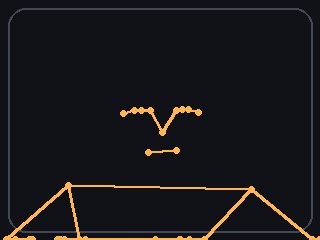
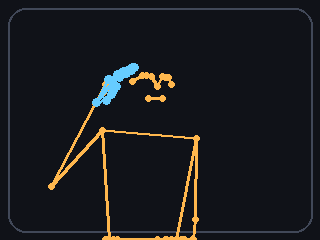
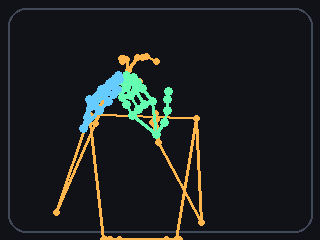
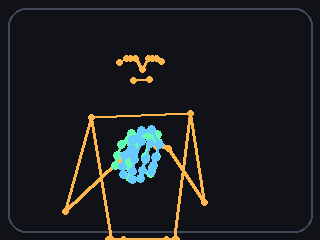
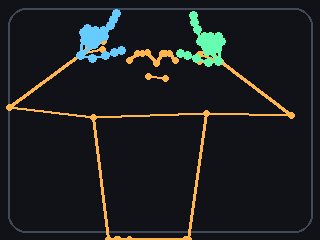
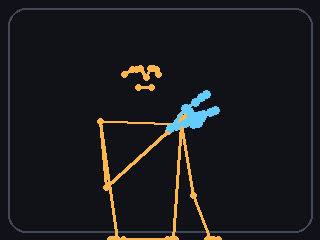

W0000 00:00:1773391477.903011  232046 landmark_projection_calculator.cc:186] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


In [ ]:
from base64 import b64encode
from io import BytesIO
from pathlib import Path

from IPython.display import HTML, display
from PIL import Image, ImageDraw

DATA_PATH = Path("Data")
CANVAS_SIZE = (320, 240)
POSE_CONNECTIONS = list(mp_holistic.POSE_CONNECTIONS)
HAND_CONNECTIONS = list(mp_holistic.HAND_CONNECTIONS)
WORDS = actions.tolist() if hasattr(actions, "tolist") else list(actions)


def split_keypoints(keypoints):
    pose_end = 33 * 4
    hand_end = pose_end + 21 * 3
    pose = keypoints[:pose_end].reshape(33, 4)
    left_hand = keypoints[pose_end:hand_end].reshape(21, 3)
    right_hand = keypoints[hand_end:].reshape(21, 3)
    return pose, left_hand, right_hand


def has_point(point):
    return not np.allclose(point[:2], 0)


def point_xy(point, canvas_size):
    width, height = canvas_size
    x = int(np.clip(float(point[0]), 0.0, 1.0) * (width - 1))
    y = int(np.clip(float(point[1]), 0.0, 1.0) * (height - 1))
    return x, y


def draw_points(draw, points, connections, color, canvas_size, radius=3, width=3):
    for start, end in connections:
        if has_point(points[start]) and has_point(points[end]):
            draw.line(
                [point_xy(points[start], canvas_size), point_xy(points[end], canvas_size)],
                fill=color,
                width=width,
            )

    for point in points:
        if has_point(point):
            x, y = point_xy(point, canvas_size)
            draw.ellipse((x - radius, y - radius, x + radius, y + radius), fill=color)


def render_sequence_frame(keypoints, canvas_size=CANVAS_SIZE):
    pose, left_hand, right_hand = split_keypoints(keypoints)
    image = Image.new("RGB", canvas_size, (16, 18, 24))
    draw = ImageDraw.Draw(image)
    draw.rounded_rectangle((8, 8, canvas_size[0] - 8, canvas_size[1] - 8), radius=18, outline=(65, 72, 88), width=2)
    draw_points(draw, pose, POSE_CONNECTIONS, (255, 183, 77), canvas_size, radius=3, width=3)
    draw_points(draw, left_hand, HAND_CONNECTIONS, (102, 255, 178), canvas_size, radius=4, width=3)
    draw_points(draw, right_hand, HAND_CONNECTIONS, (102, 204, 255), canvas_size, radius=4, width=3)
    return image


def render_motion_gif(action, sequence_index=None):
    action_dir = DATA_PATH / action
    if not action_dir.exists():
        raise FileNotFoundError(f"Missing data for action: {action}")

    if sequence_index is None:
        sequence_dirs = sorted(
            [path for path in action_dir.iterdir() if path.is_dir()],
            key=lambda path: int(path.name),
        )
        if not sequence_dirs:
            raise FileNotFoundError(f"No sequence folders found for action: {action}")
        sequence_dir = sequence_dirs[0]
    else:
        sequence_dir = action_dir / str(sequence_index)

    frame_paths = sorted(sequence_dir.glob("*.npy"), key=lambda path: int(path.stem))
    if not frame_paths:
        raise FileNotFoundError(f"No frames found in: {sequence_dir}")

    frames = [render_sequence_frame(np.load(frame_path)) for frame_path in frame_paths]
    buffer = BytesIO()
    frames[0].save(
        buffer,
        format="GIF",
        save_all=True,
        append_images=frames[1:],
        duration=90,
        loop=0,
    )
    return b64encode(buffer.getvalue()).decode("ascii"), sequence_dir.name


cards = []
for word in WORDS:
    gif_data, seq_name = render_motion_gif(word)
    cards.append(
        f"""
        <div style='background:#141824;border:1px solid #2a3142;border-radius:18px;padding:14px;width:340px;'>
          <div style='display:flex;justify-content:space-between;align-items:center;margin-bottom:10px;'>
            <strong style='font-size:18px;color:#f5f7ff'>{word}</strong>
            <span style='font-size:12px;color:#9fb0d0'>sequence {seq_name}</span>
          </div>
          <img src='data:image/gif;base64,{gif_data}' style='width:100%;border-radius:12px;border:1px solid #394359;' alt='{word} motion preview' />
        </div>
        """
    )

display(
    HTML(
        """
        <div style='margin:12px 0 16px;'>
          <h3 style='margin:0 0 6px;color:#f5f7ff'>Motion Preview For Trained Words</h3>
          <p style='margin:0;color:#aeb8cc'>These GIFs are reconstructed from the saved landmark sequences used by the model.</p>
        </div>
        <div style='display:flex;flex-wrap:wrap;gap:14px;'>
        """
        + "".join(cards)
        + "</div>"
    )
)
